# Project 3: Checkpoint 1 

This part of the project expects you to select a dataset, explore your data, filter it, and decide on questions you will answer. This checkpoint is likely to take 2-3 hours. 

## Grading Criteria 

All project checkpoints are graded on the following criteria. **You must have satisfactory completeness** when this assignment is **first due**. You will know you have satisfactory completeness by having code in every code cell that attempts to answer the question and runs, and a text cell following each code cell for every manually graded task. 

<details>

| **Criteria**            | **Excellent** | **Satisfactory** | **Revise** | **Not Assessable** |
|-------------------------|---------------|------------------|------------|---------------------|
| **Completeness**        | All required components are fully completed. The work goes beyond minimum requirements, with attention to detail and clear structure. | Most components are completed as required. Minor elements may be missing or incomplete, but the core work is present and functional. | Several key parts are missing, incomplete, or incorrect. Some progress is made, but the submission lacks important elements. | Very little or none of the required work is present. Submission is incomplete or off-topic. |
| **Justifying Choices**  | Clear and thoughtful justification is given for all major decisions. Demonstrates awareness of alternatives and logical reasoning. | Reasoning is provided for most decisions. Justifications are basic but show effort to explain choices. | Reasoning is limited, unclear, or superficial. Many decisions are unexplained or poorly justified. | No meaningful justification is provided. Decisions appear arbitrary or are copied without explanation. |
| **Coding Practices**    | Code is correct, runs without errors, and clearly applies methods or techniques taught in class. The code is well-organized, uses meaningful variable names, and is easy to follow. Comments enhance clarity. | Code mostly works and shows a clear attempt to use appropriate class-taught methods. There may be minor errors or inconsistencies, but the logic is mostly sound. Code is readable, though may lack polish or full clarity. | Code has significant issues (e.g., some of it does not run, gives incorrect output, or follows flawed logic). May not use methods from class or apply them incorrectly. Readability is poor or confusing, with unclear structure or variable names. | Code is substantially missing, does not run, or shows no understanding of class-taught concepts. May be copied, off-topic, or nonsensical. |
| **Visualization Quality (if applicable)** | Visualizations are clear, appropriate, well-labeled, and enhance understanding. Thoughtful choices of chart types and formatting. | Visualizations are generally appropriate and correctly formatted. Some labels or design choices could be improved. | Visualizations are present but may be unclear, mislabeled, or poorly chosen. Minimal effort to align visuals with data meaning. | Visualizations are missing, incorrect, or irrelevant to the task. |
| **Accurate Interpretation** | Interpretations are accurate, well-supported, and clearly communicated. Student demonstrates strong understanding of results. | Interpretations are mostly accurate and reasonable. May lack depth or precision, but show basic understanding. | Interpretations contain misunderstandings or are too vague. Some conclusions may not align with the data. | No interpretation is provided, or interpretations are clearly incorrect or misleading. |
    
</details>


## Dataset Selection. 

Before beginning, you should have located a dataset you are interested in. I recommend using https://datasetsearch.research.google.com/ as an excellent source of real-world datasets. 

Your dataset should be: 
* **tabular**  (this is a filter you can select in "Download Format")
* **Free** 
* At least 500 rows! 
* NOT a dataset that is featured on Kaggle or Tidy Tuesday 

Furthermore, to proceed in this project, you will need at least three columns that are **numeric**. There's also additional benefits for one column containing time data and/or text data and/or categorical data, but these are not necessary (they just give you further options at the end of the term). 

**You should not spend more than 1 hour looking for a dataset. Pick the best one that you can find in that period of time as long as it satisfies the above criteria. As you have seen in the previous projects, it is possible to get interesting analyses from all sorts of datasets!**

### 1. Load and Describe data. 

a) What dataset did you select? Provide a source (link to a DOI). What drew you to this dataset, and what sorts of things do you want to know about it? [Justifying Choices] 

b) Create a code cell, import `pandas` with the alias `pd`, then load your dataset and save it as an object  with a sensible name. Use .head() to make sure it has loaded correctly. [Coding Practices / Visualization ]

c) Then, in a text cell below, describe what "individual" each row of the dataframe represents. [Accurate Interpretation]

d) In a second text cell, answer: What information do you have about how this data was gathered? What groups of individuals do you expect your data analysis to apply to? [Justifying Choices]

I selected [this](https://data.chhs.ca.gov/dataset/major-diagnostic-categories-summary) dataset on hospitals in California because I was interested in hospital costs. I would love to know how length of stay and year impact the predicted cost of a visit. It would also be nice to know how this differs based on other categories, but those two are numeric.

In [1]:
import pandas as pd
import plotly.express as px

In [2]:
hospitals = pd.read_csv("data/major-diagnostic-categories-summary.csv")

hospitals.head()

,Discharge_Yr,OSHPD_ID,FACILITY_NAME,Hospital_County,Hospital_Zip,TypeCare,Adjusted_Length_of_Stay,MDC,Payer,Discharges,Valid_Charges
0,2011,10735,ALAMEDA HOSPITAL,Alameda,94501,Acute Care,1,ALCOHOL-DRUG USE AND ALCOHOL-DRUG INDUCED ORGA...,Managed Care - KNOX-KEENE/Medi-Cal County Orga...,2,26216
1,2011,10735,ALAMEDA HOSPITAL,Alameda,94501,Acute Care,1,ALCOHOL-DRUG USE AND ALCOHOL-DRUG INDUCED ORGA...,Managed Care - Other,4,65415
2,2011,10735,ALAMEDA HOSPITAL,Alameda,94501,Acute Care,1,ALCOHOL-DRUG USE AND ALCOHOL-DRUG INDUCED ORGA...,Not Applicable,3,48939
3,2011,10735,ALAMEDA HOSPITAL,Alameda,94501,Acute Care,1,ALCOHOL-DRUG USE AND ALCOHOL-DRUG INDUCED ORGA...,Traditional Coverage,2,30886
4,2011,10735,ALAMEDA HOSPITAL,Alameda,94501,Acute Care,1,"BLOOD, BLOOD FORMING ORGANS,IMMUNOLOGICAL, DIS...",Managed Care - KNOX-KEENE/Medi-Cal County Orga...,2,30406


In [3]:
aggregation_func = {'Discharge_Yr':"first", 'OSHPD_ID':"first", 'FACILITY_NAME':"first", 'Hospital_County':"first",
       'Hospital_Zip':"first", 'TypeCare':"first", 'Adjusted_Length_of_Stay':"median", 'MDC':"first",
       'Discharges':"sum", 'Valid_Charges':"sum"}
hospitals_filtered = hospitals.drop(columns="Payer").groupby(by=["Discharge_Yr", "OSHPD_ID", "MDC", "Adjusted_Length_of_Stay"], as_index=False).aggregate(aggregation_func)

# get the average charges so we can have a better individual estimate on cost
hospitals_filtered["Average_Charges"] = hospitals_filtered["Valid_Charges"]/hospitals_filtered["Discharges"]
hospitals_filtered.head()

,Discharge_Yr,OSHPD_ID,FACILITY_NAME,Hospital_County,Hospital_Zip,TypeCare,Adjusted_Length_of_Stay,MDC,Discharges,Valid_Charges,Average_Charges
0,2011,10735,ALAMEDA HOSPITAL,Alameda,94501,Acute Care,1.0,ALCOHOL-DRUG USE AND ALCOHOL-DRUG INDUCED ORGA...,11,171456,15586.909091
1,2011,10735,ALAMEDA HOSPITAL,Alameda,94501,Acute Care,2.0,ALCOHOL-DRUG USE AND ALCOHOL-DRUG INDUCED ORGA...,4,92128,23032.000000
2,2011,10735,ALAMEDA HOSPITAL,Alameda,94501,Acute Care,3.0,ALCOHOL-DRUG USE AND ALCOHOL-DRUG INDUCED ORGA...,3,77956,25985.333333
3,2011,10735,ALAMEDA HOSPITAL,Alameda,94501,Acute Care,4.0,ALCOHOL-DRUG USE AND ALCOHOL-DRUG INDUCED ORGA...,4,151857,37964.250000
4,2011,10735,ALAMEDA HOSPITAL,Alameda,94501,Acute Care,6.0,ALCOHOL-DRUG USE AND ALCOHOL-DRUG INDUCED ORGA...,3,139953,46651.000000


Each row of the dataset describes a major diagnostic category of a specific hospital in California in a specific year.

This data was gathered by California's Department of Healthcare Access and Information (HCAI). My data analysis applies to individuals wanting to predict the cost of their visit to a hospital. My analysis pertains to hospital costs. 

## Individual Planning. 

### 2.  Exploring with Visualization 

a) In a code cell, obtain a list of the dataframe's columns. [Coding Practices / Visualizations ]

b) Is there any column in this dataset that makes sense as a target variable for regression in context? Explain why. [Justification]

c) To plan ahead for clustering and/or regression, create a scatter matrix visualizing the relationship between at least two numerical columns as well as your target variable. [Visualization Practices ] 

d) To plan ahead for estimation, create at least one plot (e.g. histogram/bar chart) showing the proportion of the data that belongs to a particular category, or displaying the distribution of a numerical variable you are interested in. [Visualization Practices]

In [4]:
hospitals.columns

Index(['Discharge_Yr', 'OSHPD_ID', 'FACILITY_NAME', 'Hospital_County',
       'Hospital_Zip', 'TypeCare', 'Adjusted_Length_of_Stay', 'MDC', 'Payer',
       'Discharges', 'Valid_Charges'],
      dtype='str')

I plan to use `Average_Charges` as a target variable for regression because it would be good to be able to predict the cost of a hospital visit based on different factors. 

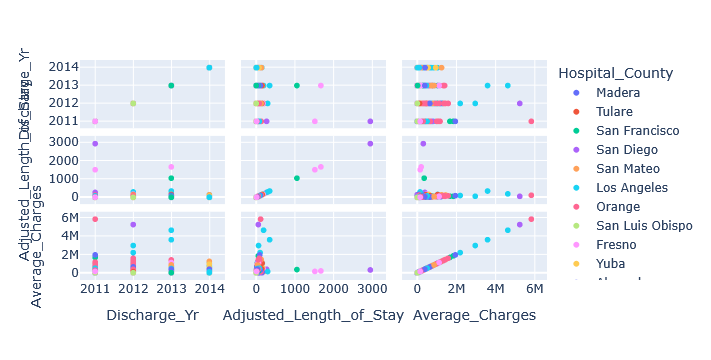

In [5]:
px.scatter_matrix(hospitals_filtered.sample(1000),
                  dimensions=["Discharge_Yr", "Adjusted_Length_of_Stay", "Average_Charges"],
                  color="Hospital_County"
)

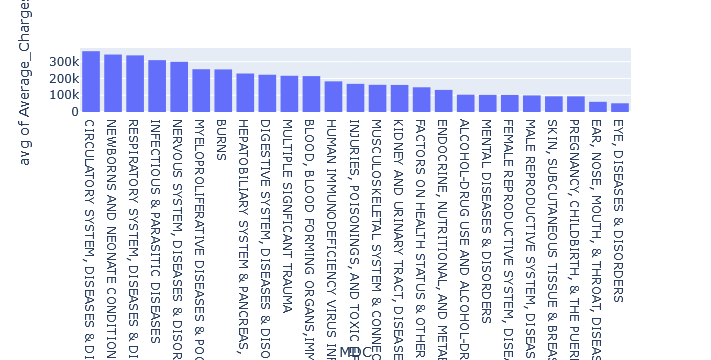

In [6]:
# d) To plan ahead for estimation, create at least one plot (e.g. histogram/bar chart) showing the proportion of the data that belongs to a particular category, or displaying the distribution of a numerical variable you are interested in. [Visualization Practices]

hist = px.histogram(hospitals_filtered.sample(1000),
             x="MDC",
             y="Average_Charges",
             histfunc="avg",
).update_layout(xaxis={'categoryorder': 'total descending'})

hist

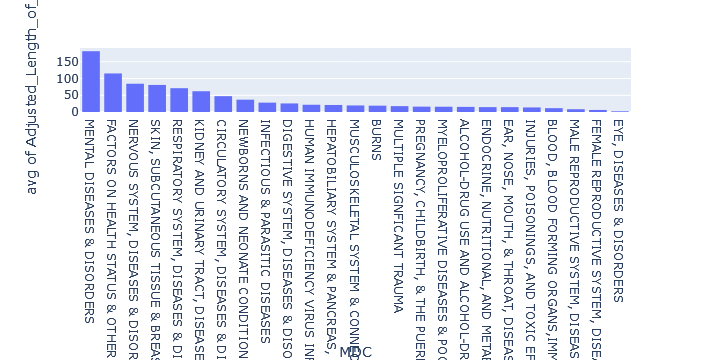

In [7]:
hist2 = px.histogram(hospitals_filtered.sample(1000),
             x="MDC",
             y="Adjusted_Length_of_Stay",
             histfunc="avg"
).update_layout(xaxis={'categoryorder': 'total descending'})

hist2

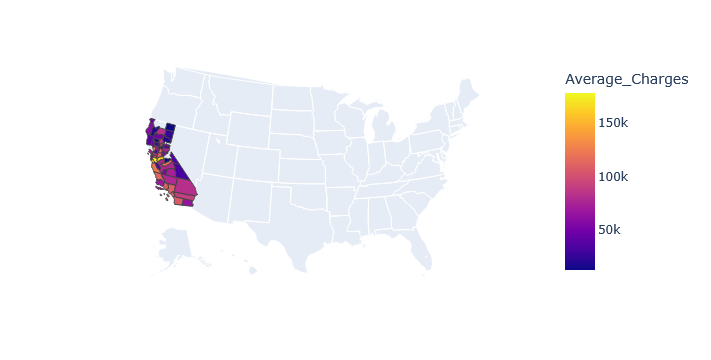

In [8]:
from urllib.request import urlopen
import json
with urlopen('https://gist.githubusercontent.com/pdbartsch/4a4ad6c68ab75d597610/raw/4adc6d41320d06e42a43e4075106932ca7b44cd5/ca_counties.geojson') as response:
    counties = json.load(response)


for_map = hospitals_filtered.groupby("Hospital_County", as_index=False)[["Hospital_County", "Average_Charges"]].agg({"Hospital_County":"first", "Average_Charges":"median"})
for_map

map = px.choropleth(for_map,
                    geojson=counties,
                    locations="Hospital_County",
                    featureidkey="properties.NAME",
                    color="Average_Charges",
                    scope="usa"
)

map

### 3. Asking Questions

a) Ask a **prediction question** about your dataset, which is appropriate to answer with **regression**. Make sure you indicate more than one preidctor variable, and one response variable?

b) Explain how you know that regression is the appropriate data tool to use to answer your prediction question. 

c) Ask an **inference question** about your dataset, which is appropriate to answer with **estimation** of a population mean or proportion. That is, ask a question like, "From a group larger than my dataset, what is the average $\underline{\hspace{1in}}$ where  $\underline{\hspace{1in}}$ is a column in my dataset" or "what is the proportion of  $\underline{\hspace{1in}}$ in a larger population than my dataset?" 

* For full credit, make it clear what *larger population/group* your dataset *might* be able to generalize to, make it clear *what* column you are looking at, and whether you are estimating an *average* or a *proportion*.  


My prediction question is: how can length of stay and year impact the predicted cost of a visit?

I know that regression is appropriate because cost is a numerical value. 

From a group larger than my dataset, what is the average length of stay where ‾​ is a column in my dataset" or "what is the proportion of ‾​ in a larger population than my dataset?

### 4. Cleaning and Saving Data 

a) Create a code cell, and filter your dataset to the columns you are analyzing, saving your filtered data frame to a new object with a different name. If you want to focus only on specific groups, you can filter rows, but make sure you keep all the rows you are interested in. [Coding Practices]

b) You might need to clean your data. If so, do so here. This could be reshaping your data frame, combining columns, etc. You no longer need to remove rows with NA entries if you plan to use imputers.

c). Demonstrate that you have obtained the correct filtered and cleaned data by including code that displays the the dataframe in some way. \ Visualizations]

d) In a second code cell, using `df.to_csv()`, save your filtered dataset as `name_clean_data.csv`  or similar, so you can load it later without needing to re-run these cells. [Coding Practices] 

I already did most of these steps in a cell above! Since I didn't start with many columns, I didn't need to narrow them down much. 

In [9]:
hospitals_filtered.to_csv("data/hospitals_filtered.csv")

### 5. For Excellent: take it a step further

If you did not need to clean your data (which will get you Excellent completeness credit), put some code below that explores or summarizes your data in a way you are interested in, using tools you have learned so far in this class or from our textbook. 

(If you use techniques we have not covered, you must put a link or source where you found those tools, and describe how you developed your ideas, so I can give you meaningful feedback. Without this information, I cannot give Excellent credit.) In a text cell, describe what you are doing, and why you wanted to do it. You may use some of this code on a future project checkpoint if it is applicable, or on your final report -- but you do not have to.